# 📊 Notebook 01 — Dataset Exploration & Metadata Creation

**Phase 1 & 2 of the project**

What this notebook does:
1. Walks the BreakHis folder structure
2. Parses patient ID, class, subtype, magnification from the filename
3. Creates `metadata.csv` — the master table for the entire project
4. Analyzes the dataset (class distribution, magnifications, subtypes)
5. Displays sample images

**Run each cell with Shift+Enter**

## 0. Setup & Imports

In [1]:
import sys
sys.path.insert(0, r'D:\Projects\ML')   # so Python can find src/

import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import seaborn as sns
from pathlib import Path
from collections import Counter

from src.config import (
    DATASET_DIR, METADATA_CSV, FIGURES_DIR,
    MAGNIFICATIONS, BENIGN_SUBTYPES, MALIGNANT_SUBTYPES, CLASS_MAP
)
from src.utils import set_plot_style, save_figure, set_seed

set_plot_style()
set_seed(42)
print('✅ Imports done!')
print(f'📁 Dataset path: {DATASET_DIR}')
print(f'   Exists: {DATASET_DIR.exists()}')

🌱  Random seed set to 42
✅ Imports done!
📁 Dataset path: D:\Projects\ML\dataset\BreaKHis_v1\histology_slides\breast
   Exists: True


## 1. Understand the Folder Structure

In [2]:
# Print the top-level structure so you understand how it's organised
print('BreakHis Dataset Structure:\n')
for class_dir in sorted(DATASET_DIR.iterdir()):
    if class_dir.is_dir():
        print(f'  📂 {class_dir.name}/')
        sob_dir = class_dir / 'SOB'
        if sob_dir.exists():
            for subtype_dir in sorted(sob_dir.iterdir()):
                if subtype_dir.is_dir():
                    print(f'      📂 {subtype_dir.name}/')
                    # Show first patient
                    patients = sorted(subtype_dir.iterdir())
                    if patients:
                        p = patients[0]
                        print(f'          📂 {p.name}/')
                        for mag_dir in sorted(p.iterdir()):
                            imgs = list(mag_dir.glob('*.png'))
                            print(f'              📂 {mag_dir.name}/  ({len(imgs)} images)')
                    if len(patients) > 1:
                        print(f'          ... and {len(patients)-1} more patients')

BreakHis Dataset Structure:

  📂 benign/
      📂 adenosis/
          📂 SOB_B_A_14-22549AB/
              📂 100X/  (30 images)
              📂 200X/  (32 images)
              📂 400X/  (30 images)
              📂 40X/  (29 images)
          ... and 3 more patients
      📂 fibroadenoma/
          📂 SOB_B_F_14-14134/
              📂 100X/  (31 images)
              📂 200X/  (38 images)
              📂 400X/  (37 images)
              📂 40X/  (36 images)
          ... and 9 more patients
      📂 phyllodes_tumor/
          📂 SOB_B_PT_14-21998AB/
              📂 100X/  (66 images)
              📂 200X/  (52 images)
              📂 400X/  (59 images)
              📂 40X/  (58 images)
          ... and 2 more patients
      📂 tubular_adenoma/
          📂 SOB_B_TA_14-13200/
              📂 100X/  (14 images)
              📂 200X/  (21 images)
              📂 400X/  (15 images)
              📂 40X/  (15 images)
          ... and 6 more patients
  📂 malignant/
      📂 ductal_carcinoma/
          

## 2. Parse Filename & Build metadata.csv

Example filename: `SOB_B_A_14-22549AB-40-001.png`
- `SOB` = Slide On Board
- `B` = Benign (or `M` = Malignant)  
- `A` = Adenosis (subtype code)
- `14-22549AB` = Patient ID
- `40` = Magnification factor
- `001` = Image index

In [3]:
records = []

for class_name in ['benign', 'malignant']:
    class_dir = DATASET_DIR / class_name / 'SOB'
    if not class_dir.exists():
        print(f'⚠️  Not found: {class_dir}')
        continue

    for subtype_dir in sorted(class_dir.iterdir()):
        if not subtype_dir.is_dir():
            continue
        subtype = subtype_dir.name   # e.g. 'adenosis'

        for patient_dir in sorted(subtype_dir.iterdir()):
            if not patient_dir.is_dir():
                continue
            patient_id = patient_dir.name   # e.g. 'SOB_B_A_14-22549AB'

            for mag_dir in sorted(patient_dir.iterdir()):
                if not mag_dir.is_dir():
                    continue
                magnification = mag_dir.name   # e.g. '40X'

                for img_path in sorted(mag_dir.glob('*.png')):
                    records.append({
                        'image_path':    str(img_path),
                        'patient_id':    patient_id,
                        'class_name':    class_name,
                        'label':         CLASS_MAP[class_name],
                        'subtype':       subtype,
                        'magnification': magnification,
                    })

metadata = pd.DataFrame(records)
metadata.to_csv(METADATA_CSV, index=False)

print(f'✅ metadata.csv created!')
print(f'   Total images : {len(metadata)}')
print(f'   Total patients: {metadata["patient_id"].nunique()}')
print(f'   Saved to: {METADATA_CSV}')
metadata.head()

✅ metadata.csv created!
   Total images : 7909
   Total patients: 82
   Saved to: D:\Projects\ML\metadata.csv


,image_path,patient_id,class_name,label,subtype,magnification
0,D:\Projects\ML\dataset\BreaKHis_v1\histology_s...,SOB_B_A_14-22549AB,benign,0,adenosis,100X
1,D:\Projects\ML\dataset\BreaKHis_v1\histology_s...,SOB_B_A_14-22549AB,benign,0,adenosis,100X
2,D:\Projects\ML\dataset\BreaKHis_v1\histology_s...,SOB_B_A_14-22549AB,benign,0,adenosis,100X
3,D:\Projects\ML\dataset\BreaKHis_v1\histology_s...,SOB_B_A_14-22549AB,benign,0,adenosis,100X
4,D:\Projects\ML\dataset\BreaKHis_v1\histology_s...,SOB_B_A_14-22549AB,benign,0,adenosis,100X


## 3. Dataset Statistics

In [4]:
print('='*55)
print('           BREAKHIS DATASET SUMMARY')
print('='*55)
print(f'  Total images          : {len(metadata):,}')
print(f'  Total unique patients : {metadata["patient_id"].nunique():,}')
print()
print('  Class Distribution:')
for cls, grp in metadata.groupby('class_name'):
    pct = len(grp)/len(metadata)*100
    print(f'    {cls.capitalize():12s}: {len(grp):5,} images  ({pct:.1f}%)')
print()
print('  Magnification Distribution:')
for mag in ['40X','100X','200X','400X']:
    n = len(metadata[metadata['magnification']==mag])
    print(f'    {mag:6s}: {n:5,} images')
print()
print('  Subtype Distribution:')
for subtype, grp in metadata.groupby('subtype'):
    cls = grp['class_name'].iloc[0].capitalize()
    print(f'    {subtype:25s} [{cls}]: {len(grp):5,}')
print('='*55)

           BREAKHIS DATASET SUMMARY
  Total images          : 7,909
  Total unique patients : 82

  Class Distribution:
    Benign      : 2,480 images  (31.4%)
    Malignant   : 5,429 images  (68.6%)

  Magnification Distribution:
    40X   : 1,995 images
    100X  : 2,081 images
    200X  : 2,013 images
    400X  : 1,820 images

  Subtype Distribution:
    adenosis                  [Benign]:   444
    ductal_carcinoma          [Malignant]: 3,451
    fibroadenoma              [Benign]: 1,014
    lobular_carcinoma         [Malignant]:   626
    mucinous_carcinoma        [Malignant]:   792
    papillary_carcinoma       [Malignant]:   560
    phyllodes_tumor           [Benign]:   453
    tubular_adenoma           [Benign]:   569


## 4. Visualizations

📊  Saved figure → D:\Projects\ML\outputs\figures\01_dataset_distributions.png


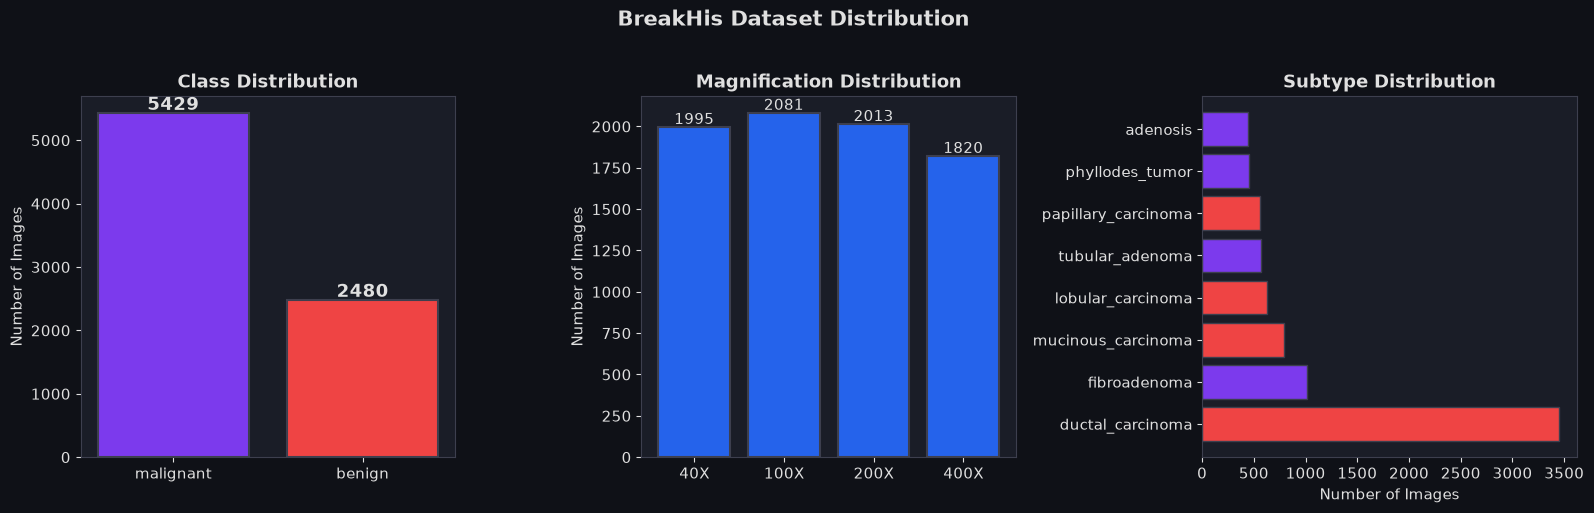

In [5]:
# ── Figure 1: Class distribution ──────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle('BreakHis Dataset Distribution', fontsize=15, y=1.02)
PALETTE = ['#7c3aed', '#ef4444']

# --- Benign vs Malignant ---
class_counts = metadata['class_name'].value_counts()
axes[0].bar(class_counts.index, class_counts.values,
            color=PALETTE, edgecolor='#3d3f4e', linewidth=1.5)
for i, (cls, cnt) in enumerate(class_counts.items()):
    axes[0].text(i, cnt + 50, str(cnt), ha='center', fontsize=13, fontweight='bold')
axes[0].set_title('Class Distribution')
axes[0].set_ylabel('Number of Images')

# --- Magnification ---
mag_counts = metadata['magnification'].value_counts().reindex(['40X','100X','200X','400X'])
axes[1].bar(mag_counts.index, mag_counts.values,
            color='#2563eb', edgecolor='#3d3f4e', linewidth=1.5)
for i, cnt in enumerate(mag_counts.values):
    axes[1].text(i, cnt + 20, str(cnt), ha='center', fontsize=11)
axes[1].set_title('Magnification Distribution')
axes[1].set_ylabel('Number of Images')

# --- Subtype ---
subtype_counts = metadata['subtype'].value_counts()
colors_sub = [PALETTE[0] if s in BENIGN_SUBTYPES else PALETTE[1]
              for s in subtype_counts.index]
axes[2].barh(subtype_counts.index, subtype_counts.values,
             color=colors_sub, edgecolor='#3d3f4e', linewidth=1)
axes[2].set_title('Subtype Distribution')
axes[2].set_xlabel('Number of Images')

plt.tight_layout()
save_figure(fig, FIGURES_DIR / '01_dataset_distributions.png')
plt.show()

📊  Saved figure → D:\Projects\ML\outputs\figures\01_images_per_patient.png


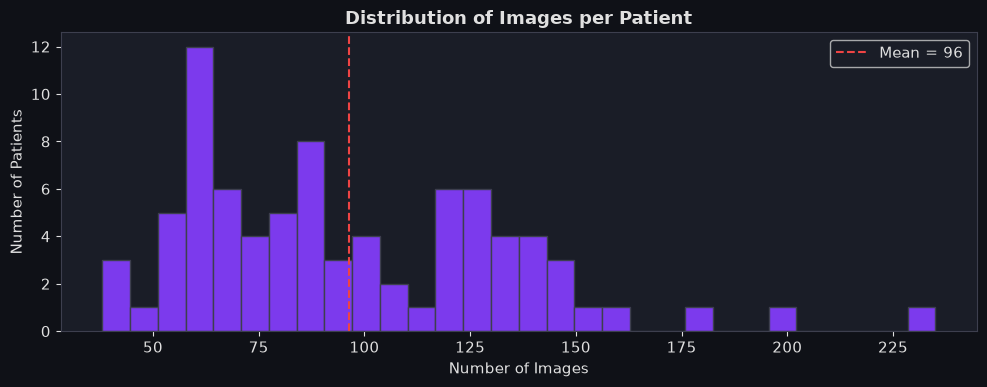

Min images per patient: 38
Max images per patient: 235
Mean images per patient: 96.5


In [6]:
# ── Figure 2: Images per patient ─────────────────────────────────────────────
imgs_per_patient = metadata.groupby('patient_id').size()
fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(imgs_per_patient.values, bins=30, color='#7c3aed',
        edgecolor='#3d3f4e', linewidth=1)
ax.set_title('Distribution of Images per Patient')
ax.set_xlabel('Number of Images')
ax.set_ylabel('Number of Patients')
ax.axvline(imgs_per_patient.mean(), color='#ef4444',
           linestyle='--', label=f'Mean = {imgs_per_patient.mean():.0f}')
ax.legend()
plt.tight_layout()
save_figure(fig, FIGURES_DIR / '01_images_per_patient.png')
plt.show()
print(f'Min images per patient: {imgs_per_patient.min()}')
print(f'Max images per patient: {imgs_per_patient.max()}')
print(f'Mean images per patient: {imgs_per_patient.mean():.1f}')

📊  Saved figure → D:\Projects\ML\outputs\figures\01_sample_images.png


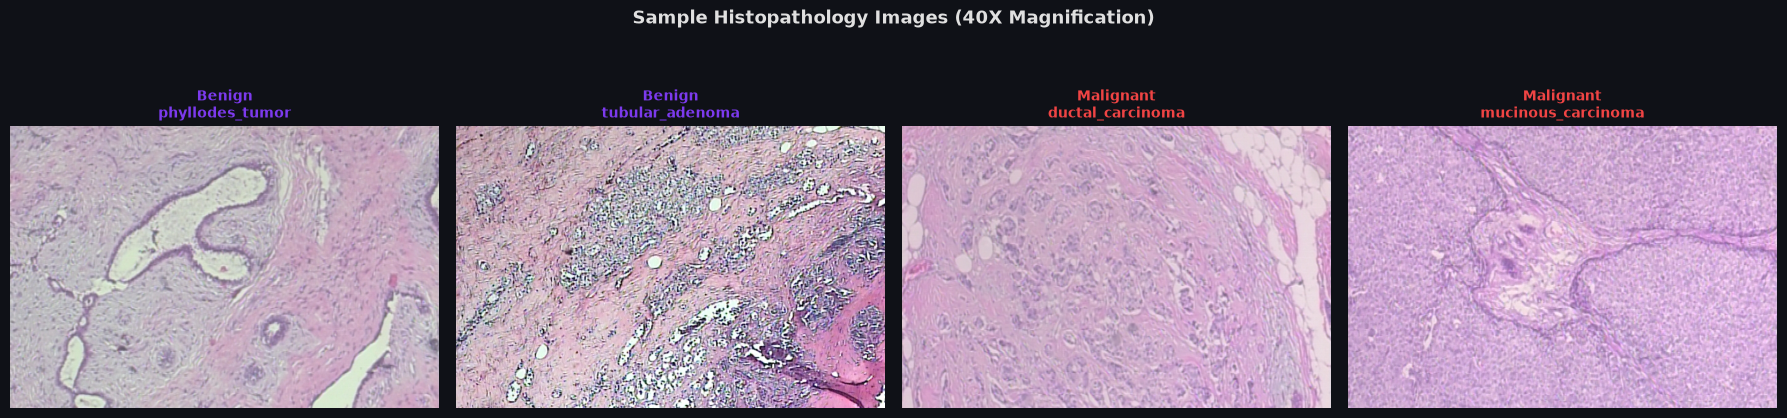

In [7]:
# ── Figure 3: Sample Images ───────────────────────────────────────────────────
import cv2

# Pick 2 benign + 2 malignant sample images
samples = []
for cls in ['benign', 'malignant']:
    subset = metadata[(metadata['class_name']==cls) & (metadata['magnification']=='40X')]
    samples.extend(subset.sample(2, random_state=42).to_dict('records'))

fig, axes = plt.subplots(1, 4, figsize=(18, 5))
fig.suptitle('Sample Histopathology Images (40X Magnification)', fontsize=13)

for ax, rec in zip(axes, samples):
    img = cv2.imread(rec['image_path'])
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    ax.imshow(img_rgb)
    ax.set_title(f"{rec['class_name'].capitalize()}\n{rec['subtype']}",
                 fontsize=10,
                 color='#ef4444' if rec['class_name']=='malignant' else '#7c3aed')
    ax.axis('off')

plt.tight_layout()
save_figure(fig, FIGURES_DIR / '01_sample_images.png')
plt.show()

📊  Saved figure → D:\Projects\ML\outputs\figures\01_magnification_comparison.png


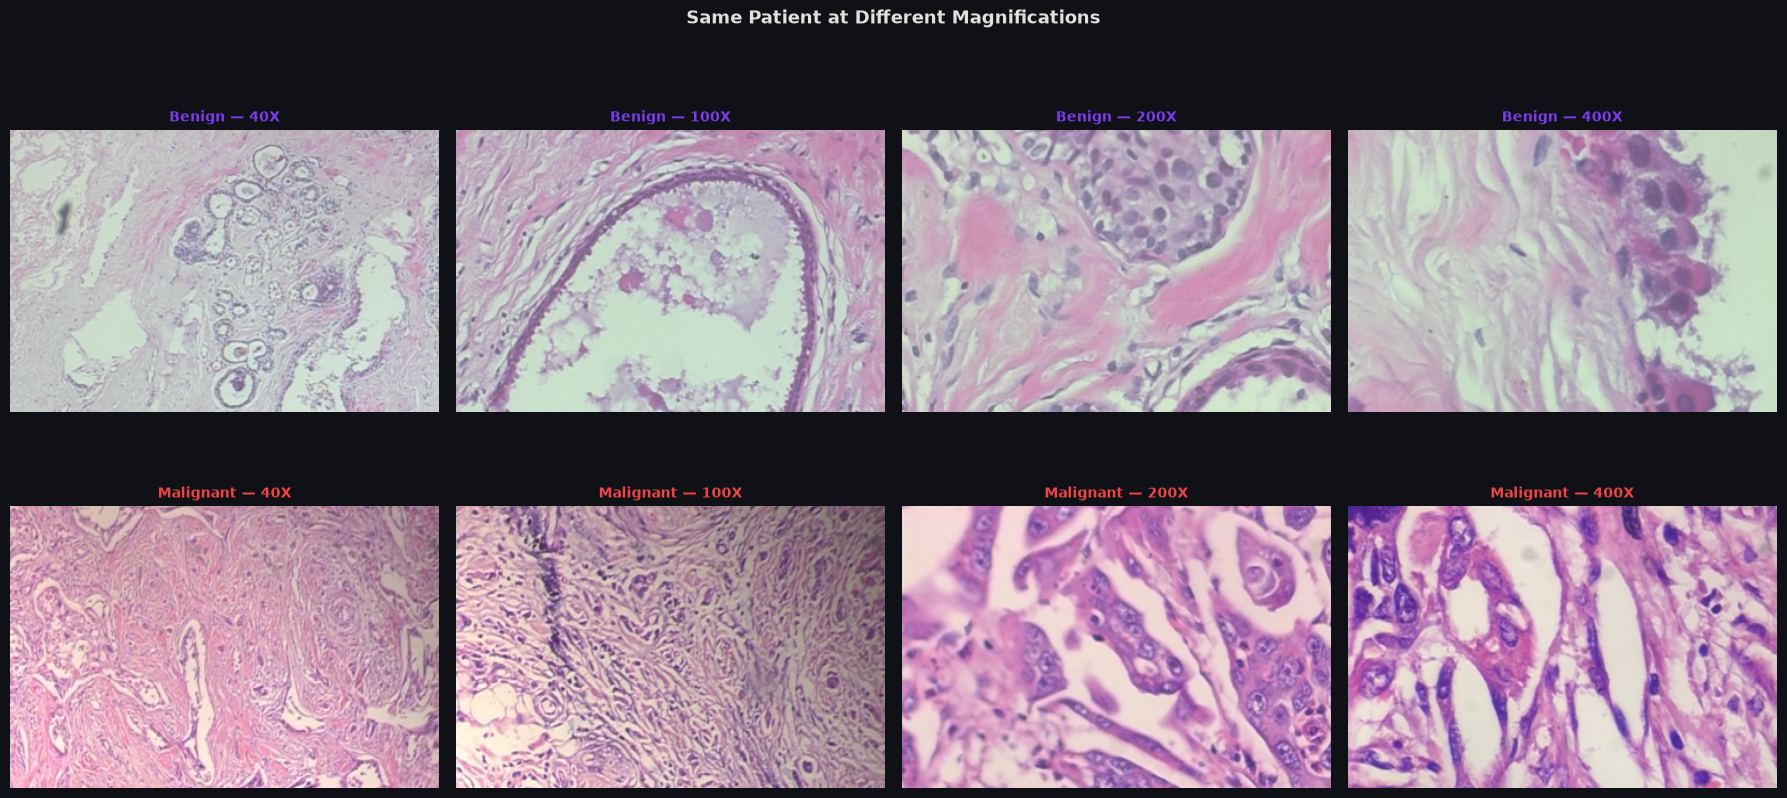

In [8]:
# ── Figure 4: Sample images across all magnifications ─────────────────────────
# Pick one benign and one malignant patient, show all 4 magnifications
fig, axes = plt.subplots(2, 4, figsize=(18, 9))
fig.suptitle('Same Patient at Different Magnifications', fontsize=13)

for row, cls in enumerate(['benign', 'malignant']):
    # Get a patient with images at all 4 magnifications
    patient = None
    for pid, grp in metadata[metadata['class_name']==cls].groupby('patient_id'):
        if set(grp['magnification'].unique()) == {'40X','100X','200X','400X'}:
            patient = pid
            break

    for col, mag in enumerate(['40X','100X','200X','400X']):
        row_df = metadata[(metadata['patient_id']==patient) &
                          (metadata['magnification']==mag)]
        if len(row_df) == 0:
            axes[row, col].axis('off')
            continue
        img_path = row_df.iloc[0]['image_path']
        img = cv2.imread(img_path)
        img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        axes[row, col].imshow(img_rgb)
        axes[row, col].set_title(f'{cls.capitalize()} — {mag}', fontsize=10,
            color='#ef4444' if cls=='malignant' else '#7c3aed')
        axes[row, col].axis('off')

plt.tight_layout()
save_figure(fig, FIGURES_DIR / '01_magnification_comparison.png')
plt.show()

## 5. Summary — What We Know About Our Dataset

In [9]:
n_benign = len(metadata[metadata['class_name']=='benign'])
n_malignant = len(metadata[metadata['class_name']=='malignant'])
n_patients = metadata['patient_id'].nunique()

print('='*60)
print('  ✅  PHASE 1 & 2 COMPLETE — Dataset Summary')
print('='*60)
print(f'  Total images   : {len(metadata):,}')
print(f'  Benign images  : {n_benign:,}  ({n_benign/len(metadata)*100:.1f}%)')
print(f'  Malignant imgs : {n_malignant:,}  ({n_malignant/len(metadata)*100:.1f}%)')
print(f'  Total patients : {n_patients}')
print(f'  Magnifications : 40X, 100X, 200X, 400X')
print(f'  Benign subtypes: adenosis, fibroadenoma, phyllodes_tumor, tubular_adenoma')
print(f'  Malignant subs : ductal_carcinoma, lobular_carcinoma, mucinous_carcinoma, papillary_carcinoma')
print()
print(f'  📄 metadata.csv saved → {METADATA_CSV}')
print(f'  📊 Figures saved → {FIGURES_DIR}')
print()
print('  ➡️  Next: Notebook 02 — Patient-Level Data Splitting')
print('='*60)

  ✅  PHASE 1 & 2 COMPLETE — Dataset Summary
  Total images   : 7,909
  Benign images  : 2,480  (31.4%)
  Malignant imgs : 5,429  (68.6%)
  Total patients : 82
  Magnifications : 40X, 100X, 200X, 400X
  Benign subtypes: adenosis, fibroadenoma, phyllodes_tumor, tubular_adenoma
  Malignant subs : ductal_carcinoma, lobular_carcinoma, mucinous_carcinoma, papillary_carcinoma

  📄 metadata.csv saved → D:\Projects\ML\metadata.csv
  📊 Figures saved → D:\Projects\ML\outputs\figures

  ➡️  Next: Notebook 02 — Patient-Level Data Splitting
